In [71]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [72]:
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,"[bash, python, perl, linux, unix, kubernetes, ...","{'os': ['linux', 'unix'], 'other': ['kubernete..."
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,"[sas, sas, sql, excel]","{'analyst_tools': ['sas', 'excel'], 'programmi..."
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,"[powerpoint, excel]","{'analyst_tools': ['powerpoint', 'excel']}"
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,"[python, go, nosql, sql, mongo, shell, mysql, ...","{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."


### Problem #1 Statement:
Create a subplot with 2 rows and 1 column:

In the first subplot, plot a bar chart of the top 3 job locations by the number of job postings.
In the second subplot, plot a horizontal bar chart of the top 3 job titles by the number of job postings.
Use tight_layout() to adjust the spacing between subplots.

In [73]:
# top 3 job locations by the number of job postings:
series_1 = df.groupby("job_location").size()
series_1

job_location
's-Graveland, Netherlands          1
's-Gravendeel, Netherlands         2
's-Heerenberg, Netherlands         1
's-Hertogenbosch, Netherlands    292
't Harde, Netherlands              4
                                ... 
Žebrák, Czechia                    1
Žilina, Slovakia                   7
Șelimbăr, Romania                  2
محافظة جبل لبنان., Lebanon         1
จ.กรุงเทพมหานคร Thailand           1
Length: 17217, dtype: int64

In [74]:
series_1_final = series_1.sort_values(ascending=False).head(3)
series_1_final

job_location
Anywhere         69552
Singapore        23415
Paris, France    12311
dtype: int64

In [75]:
# top 3 job titles by the number of job postings
series_2 = df.groupby("job_title").size()
series_2

job_title
!! Data Engineer [W2] | FULLY REMOTE | Immediate Opportunity!!          1
!!urgent Hiring!! AWS Lead data engineer(Hybrid,W2 candidates only )    1
!URGENT HIRING! Data Analyst (hybrid setup)                             1
!เจ้าหน้าที่วิศวกรรมข้อมูล (MIS & Analytics)                            2
"\tHead Of Analytics"                                                   1
                                                                       ..
🧑‍🔬 R&D Engineer                                                        1
🧱 Project Lead                                                          1
🧱 Senior Data Engineer                                                  1
🩺 BI Data Engineer - Medtech - H/F                                      1
🩺 Data Engineer - Medtech - H/F                                         1
Length: 234673, dtype: int64

In [76]:
series_2_final = series_2.sort_values(ascending=False).head(3)
series_2_final

job_title
Data Engineer     53908
Data Scientist    42542
Data Analyst      41950
dtype: int64

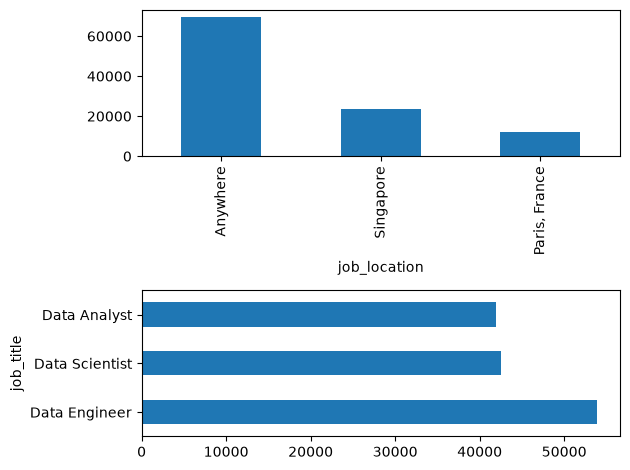

In [77]:
fig, ax = plt.subplots(2, 1)
series_1_final.plot(kind="bar", ax=ax[0], legend=False)
series_2_final.plot(kind="barh", ax=ax[1], legend=False)

fig.tight_layout()


### IMPORTANT!

Use .value_counts() when analyzing a single column, and .size() when aggregating data across multiple grouped columns.

<br>

Use ***.value_counts()*** when:
- Working on a single Series (column): You want to quickly count the frequency of unique items in one column without setting up a .groupby().

- You want automatic descending sort: It automatically orders results from highest to lowest count.

- You want to exclude NaN values by default: It drops missing values automatically (though you can pass dropna=False to keep them).

Quick count of top job titles, automatically sorted from highest to lowest
df["job_title_short"].value_counts().head(5)

<br>

Use ***.groupby().size()*** when:
- Grouping by multiple columns: You need to count occurrences across combinations of columns (e.g., skill frequency per job title).

- Counting all rows in a group (including NaN): It returns the raw row count for each group regardless of missing values inside individual cells.

- Building multi-level tables: You intend to reshape the resulting MultiIndex Series using .unstack() or .reset_index().

Counts how many times each skill appears within EACH job title
df.groupby(["job_title_short", "job_skills"]).size()

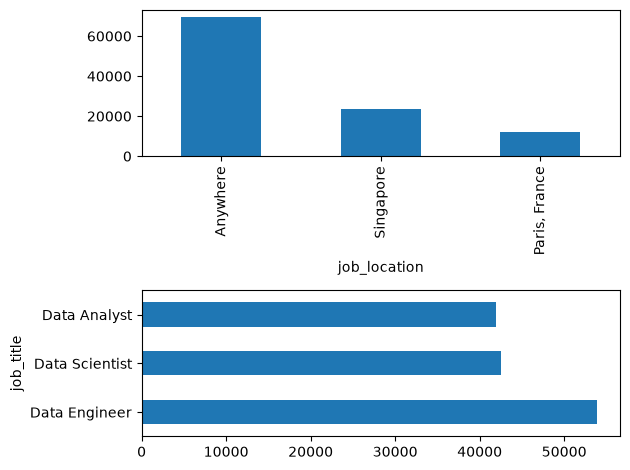

In [78]:
# solution with better flow:
# 1. Get top 3 series using value_counts()
series_1_final = df["job_location"].value_counts().head(3)
series_2_final = df["job_title"].value_counts().head(3)

# 2. Create subplots
fig, ax = plt.subplots(2, 1)

# 3. Plot data onto each axis
series_1_final.plot(kind="bar", ax=ax[0])
series_2_final.plot(kind="barh", ax=ax[1])

# 4. Adjust layout
fig.tight_layout()
plt.show()

### 3 Small Improvements to Notice

<br>

.value_counts().head(3) vs .groupby().size().sort_values():

Using .value_counts() replaces three chained methods (.groupby(), .size(), .sort_values()) with a single, cleaner method.

<br>

Removed naked variable calls:

Lines like series_1 placed in the middle of a script don't display anything in Jupyter unless they are on the very last line of the cell, so they can safely be removed.

<br>

Optional Chart Polish (Titles & Rotation):

Bar charts often rotate X-axis text by 90 degrees by default. If your location names look tilted on ax[0], you can fix it using ax[0].tick_params(axis='x', rotation=0) or series_1_final.plot(kind="bar", ax=ax[0], rot=0).

### Problem #2 Statement:
Create a subplot with 2 rows and 2 columns:

In each subplot, plot a bar chart of the top 3 job titles by the number of job postings for each job schedule type (Full-time, Part-time, Contractor, and Internship).
Use fig.tight_layout() to adjust the spacing between subplots.

In [79]:
# top 3 job titles by the number of job postings for each job schedule type (Full-time)

df_Fulltime = df[df["job_schedule_type"] == "Full-time"] # dataframe for jobs which are Fulltime
df_Fulltime

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785702,Business Analyst,Aeronautical Analyst,"Gdańsk, Poland",via Praca Trabajo.org,Full-time,False,Poland,2023-04-26 06:24:52,False,False,Poland,NaN,NaN,NaN,NAVBLUE,NaN,NaN
785703,Data Analyst,Data Analyst - CRYPTOGRAPHY - Full-time,Anywhere,via Snagajob,Full-time,True,"Texas, United States",2023-01-28 06:02:55,True,False,United States,NaN,NaN,NaN,Axelon Services Corporation,NaN,NaN
785704,Business Analyst,Business Analyst,"Prague, Czechia",via Trabajo.org,Full-time,False,Czechia,2023-01-16 06:35:20,False,False,Czechia,NaN,NaN,NaN,Cleverlance,NaN,NaN
785705,Data Analyst,Expert Business Data Analyst - Now Hiring,"Oakland, CA",via Snagajob,Full-time,False,"California, United States",2023-01-09 06:00:25,False,False,United States,NaN,NaN,NaN,PG&E Corporation,"[sql, python, tableau]","{'analyst_tools': ['tableau'], 'programming': ..."


In [80]:
df_Fulltime["job_title"].value_counts(ascending=False).head(3) # value_counts because I am counting on a single series(single column)

job_title
Data Engineer     48345
Data Scientist    38920
Data Analyst      36534
Name: count, dtype: int64

In [81]:
# top 3 job titles by the number of job postings for each job schedule type (Part-time)
df_Parttime = df[df["job_schedule_type"] == "Part-time"]
df_Parttime

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
123,Data Analyst,Data Analytics work from home job/internship a...,Anywhere,via LinkedIn,Part-time,True,India,2023-03-07 13:37:56,False,False,India,NaN,NaN,NaN,Inoket Solutions Private Limited,"[sql, excel, word, powerpoint, outlook, power bi]","{'analyst_tools': ['excel', 'word', 'powerpoin..."
303,Senior Data Engineer,Senior Data Engineers (w/m/d). Job in Berlin M...,"Berlin, Germany",via My Valley Jobs Today,Part-time,False,Germany,2023-11-25 13:13:48,False,False,Germany,NaN,NaN,NaN,Bundesrechnungshof,"[sql, javascript, python, r]","{'programming': ['sql', 'javascript', 'python'..."
367,Data Scientist,ML & Data Science - Working Student - B2B Solu...,Anywhere,via LinkedIn,Part-time,True,Germany,2023-06-26 13:11:35,False,False,Germany,NaN,NaN,NaN,JustWatch,"[python, snowflake, pytorch]","{'cloud': ['snowflake'], 'libraries': ['pytorc..."
480,Data Analyst,Data Analyst Bootcamp and Project Work (remot...,"Minsk, Belarus",via Moyyn,Part-time,False,Belarus,2023-10-08 13:59:44,True,False,Belarus,NaN,NaN,NaN,Moyyn,[python],{'programming': ['python']}
494,Data Scientist,Data Science (NLP Research and Analytics) work...,Anywhere,via LinkedIn,Part-time,True,India,2023-02-17 13:15:15,False,False,India,NaN,NaN,NaN,IGurus Consultancy Services LLP,"[python, django, flask, flow]","{'other': ['flow'], 'programming': ['python'],..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
784405,Data Engineer,Data Engineer*,"Karlsruhe, Germany",via BeBee,Part-time,False,Germany,2023-10-31 06:11:43,False,False,Germany,NaN,NaN,NaN,Robert Bosch Group,"[python, sql, spark, power bi]","{'analyst_tools': ['power bi'], 'libraries': [..."
784594,Senior Data Engineer,Senior Data Engineer,"Porto, Portugal",via BeBee Portugal,Part-time,False,Portugal,2023-10-04 06:16:58,True,False,Portugal,NaN,NaN,NaN,Diconium Digital Solutions,"[python, sql, java, aws, azure, redshift, kafka]","{'cloud': ['aws', 'azure', 'redshift'], 'libra..."
784924,Data Scientist,"Математик, Junior/Middle/Senior Data Scientist",Anywhere,via Rabota.by,Part-time,True,Belarus,2023-01-30 06:45:28,False,False,Belarus,NaN,NaN,NaN,Представительство ООО «Квалитет» (Российская Ф...,"[python, matlab]","{'programming': ['python', 'matlab']}"
785232,Business Analyst,Analyst,Anywhere,via LinkedIn,Part-time,True,India,2023-05-21 06:00:44,False,False,India,NaN,NaN,NaN,Blu Ocean Innovations pvt ltd,NaN,NaN


In [82]:
df_Parttime["job_title"].value_counts(ascending=False).head(3)

job_title
Data Analyst      460
Data Scientist    257
Data Engineer     241
Name: count, dtype: int64

In [83]:
# top 3 job titles by the number of job postings for each job schedule type (Contractor)
df_Contractor = df[df["job_schedule_type"] == "Contractor"]

df_Contractor["job_title"].value_counts(ascending=False).head(3)

job_title
Data Engineer     3482
Data Analyst      2752
Data Scientist    1963
Name: count, dtype: int64

In [84]:
# top 3 job titles by the number of job postings for each job schedule type (Internship)
df_Internship = df[df["job_schedule_type"] == "Internship"]

df_Internship["job_title"].value_counts(ascending=False).head(3)

job_title
Data Analyst Intern      337
Data Science Intern      257
Data Scientist Intern    228
Name: count, dtype: int64

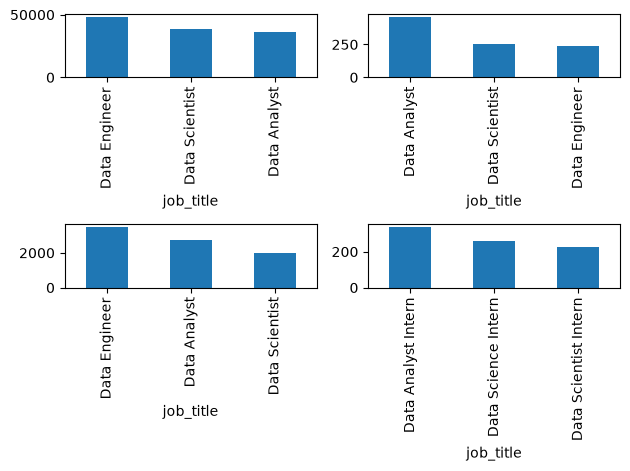

In [85]:
fig, ax = plt.subplots(2, 2) # 2 rows, in each row 2 graph columns

df_Fulltime["job_title"].value_counts(ascending=False).head(3).plot(kind="bar", ax=ax[0,0])

df_Parttime["job_title"].value_counts(ascending=False).head(3).plot(kind="bar", ax=ax[0,1])

df_Contractor["job_title"].value_counts(ascending=False).head(3).plot(kind="bar", ax=ax[1,0])

df_Internship["job_title"].value_counts(ascending=False).head(3).plot(kind="bar", ax=ax[1,1])

fig.tight_layout()

# 2D Grid Indexing: A (2, 2) grid creates a 2D array of subplots, requiring 2D coordinates like ax[row, column]:
# Top-Left: ax[0, 0]

# Top-Right: ax[0, 1]

# Bottom-Left: ax[1, 0]

# Bottom-Right: ax[1, 1]



### Problem #3 Statement:
Create a subplot with 3 rows and 1 column:

In each subplot, plot a horizontal bar chart of the top 3 job skills by the number of job postings for each job title (Senior Data Scientist, Senior Data Engineer, and Senior Data Analyst).
Use fig.tight_layout() to adjust the spacing between subplots and invert_yaxis() to invert the y-axis in each subplot.

In [ ]:
df_skills = df.explode("job_skills") # we need to explode job_skills

In [89]:
# top 3 job skills by the number of job postings for each job title (Senior Data Scientist, Senior Data Engineer, and Senior Data Analyst).

# Senior Data Scientist
df_SDS = df_skills[df_skills["job_title"] == "Senior Data Scientist"]
df_SDS["job_skills"].value_counts(ascending=False).head(3)

# Senior Data Engineer
df_SDE = df_skills[df_skills["job_title"] == "Senior Data Engineer"]
df_SDE["job_skills"].value_counts(ascending=False).head(3)

# Senior Data Analyst
df_SDA = df_skills[df_skills["job_title"] == "Senior Data Analyst"]
df_SDA["job_skills"].value_counts(ascending=False).head(3)

job_skills
sql        5932
python     3824
tableau    3425
Name: count, dtype: int64

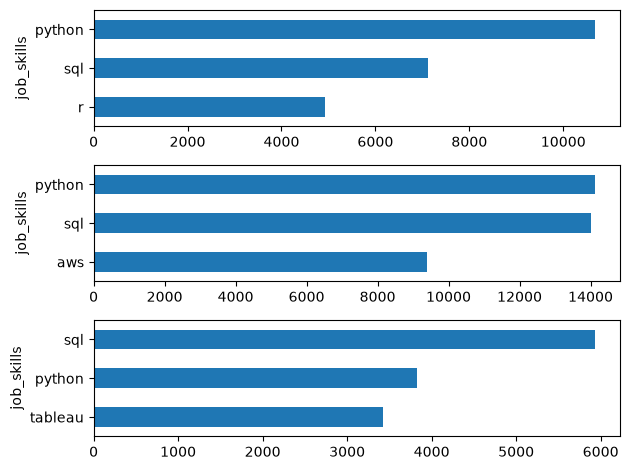

In [91]:
fig, ax = plt.subplots(3, 1)

df_SDS["job_skills"].value_counts(ascending=False).head(3).plot(kind="barh", ax=ax[0])

df_SDE["job_skills"].value_counts(ascending=False).head(3).plot(kind="barh", ax=ax[1])

df_SDA["job_skills"].value_counts(ascending=False).head(3).plot(kind="barh", ax=ax[2])

fig.tight_layout()
ax[0].invert_yaxis()
ax[1].invert_yaxis()
ax[2].invert_yaxis()

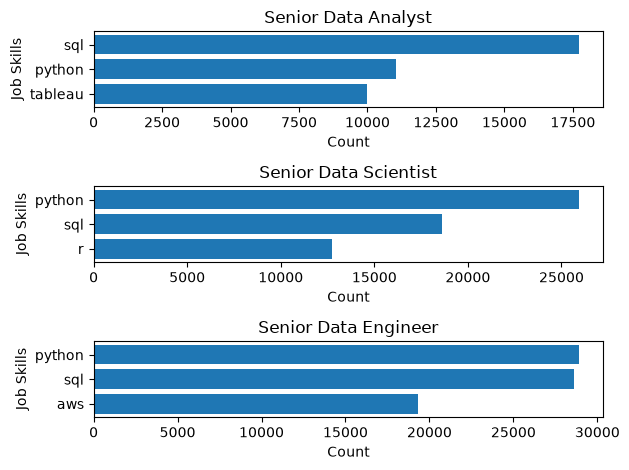

In [92]:
# The faster way(in terms of computing power):
df_skills = df.explode('job_skills')
job_roles = ['Senior Data Analyst', 'Senior Data Scientist', 'Senior Data Engineer']
fig, ax = plt.subplots(len(job_roles), 1)
for i, role in enumerate(job_roles):
    role_skills = df_skills[df_skills['job_title_short'] == role]['job_skills'].value_counts().head(3)
    ax[i].barh(role_skills.index, role_skills.values)
    ax[i].set_title(role)
    ax[i].set_xlabel('Count')
    ax[i].set_ylabel('Job Skills')
    ax[i].invert_yaxis()
fig.tight_layout()
plt.show()

df_skills = df.explode('job_skills')
- What it does: Unpacks any list of skills inside the job_skills column so each skill gets its own individual row in df_skills.

- Why: Enables .value_counts() to count individual skills (e.g., 'Python') rather than counting whole list objects (e.g., ['Python', 'SQL']).

<br>

job_roles = ['Senior Data Analyst', 'Senior Data Scientist', 'Senior Data Engineer']
- What it does: Creates a Python list containing the exact strings of the 3 job roles to plot.

- Why: Storing them in a list allows looping through them automatically instead of copying and pasting code three separate times.

fig, ax = plt.subplots(len(job_roles), 1)
- len(job_roles): Evaluates to 3 (the number of items in the list).

- plt.subplots(3, 1): Creates 1 overall Figure container (fig) and a 1D array of 3 subplot axes (ax): ax[0], ax[1], and ax[2].

<br>

for i, role in enumerate(job_roles):
- What enumerate() does: Loops through job_roles and provides two values on every step:

-- i (Index): 0 on the 1st loop, 1 on the 2nd loop, 2 on the 3rd loop.

-- role (String): 'Senior Data Analyst', 'Senior Data Scientist', 'Senior Data Engineer'.

- Why: i is used to pick the subplot box (ax[i]), while role is used to filter the data.

<br>

role_skills = df_skills[df_skills['job_title_short'] == role]['job_skills'].value_counts().head(3)
- df_skills['job_title_short'] == role: Filters df_skills down to the current loop's job title.

- ['job_skills']: Selects only the exploded skills column.

- .value_counts(): Counts how many times each skill appears for that role and sorts them descending.

- .head(3): Keeps only the top 3 most common skills.

- Result: A Pandas Series where the index contains skill names (e.g., ['SQL', 'Python', 'Tableau']) and the values contain their counts (e.g., [500, 450, 300]).

<br>

ax[i].barh(role_skills.index, role_skills.values)
- ax[i]: Targets subplot 0, 1, or 2 depending on the loop iteration.

- .barh(y, width): Matplotlib's built-in horizontal bar method:

-- role_skills.index: Passed to the y-axis (skill names).

-- role_skills.values: Passed to the x-axis (bar length/counts).

<br>

ax[i].set_title(role)
ax[i].set_xlabel('Count')
ax[i].set_ylabel('Job Skills')
ax[i].invert_yaxis()

- set_title(role): Sets the subplot title to the current role name.

- set_xlabel('Count') / set_ylabel('Job Skills'): Sets axis labels for that specific subplot.

- invert_yaxis(): Flips the vertical order so skill #1 appears at the very top of the horizontal bar chart instead of the bottom.